In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import os

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from openbabel import openbabel
from tqdm import tqdm

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
df = pd.read_csv("../halogen_EDA.csv", index_col=0)

# Halogen Type Classication

In [2]:
alkyl = '[CX4:1]([F,Cl,Br,I:2])'
ring = '[c:1]-[F,Cl,Br,I:2]'

patts = [alkyl, ring]
patts = list(map(Chem.MolFromSmarts, patts))

def find_groups(mol, idx):    
    for index, patt in enumerate(patts):
        for sub in mol.GetSubstructMatches(patt):
            if sub[1] == (idx - 1):
                if index == 0:
                    C_idx = sub[0]
                    amount = len([sub for sub in mol.GetSubstructMatches(patt) if sub[0] == C_idx])
                    # if amount >= 1:
                    #     return 'alkyl'
                    if amount == 1:
                        return 'alkyl_1'
                    elif amount == 2:
                        return 'alkyl_2'
                    elif amount == 3:
                        return 'alkyl_3'
                elif index == 1:
                    return 'ring'
    return None

groups = []
groupID = []
errs = []

for index, row in tqdm(df.iterrows()):
    try:
        mol = Chem.SDMolSupplier(os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"), removeHs=False)[0]
        groups.append(find_groups(mol, row['don_idx']))
        groupID.append([row['full_PDBID'], row['subdir'], find_groups(mol, row['don_idx'])])
    except Exception as e:
        errs.append((index, e))
        groups.append('')

df['group'] = groups

0it [00:00, ?it/s]

1318it [00:01, 1158.92it/s]


# Group Type Stats

In [3]:
df_E = df.query('TOTAL < 0')

F_alkyl1 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_1"')
F_alkyl2 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_2"')
F_alkyl3 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_3"')
F_ring = df.query('donortype == "F" & TOTAL < 0 & group == "ring"')
print('F: ')
print(len(F_alkyl1))
print(len(F_alkyl2))
print(len(F_alkyl3))
print(len(F_ring))

Cl_alkyl1 = df.query('donortype == "Cl" & TOTAL < 0 & group == "alkyl_1"')
Cl_alkyl2 = df.query('donortype == "Cl" & TOTAL < 0 & group == "alkyl_2"')
Cl_alkyl3 = df.query('donortype == "Cl" & TOTAL < 0 & group == "alkyl_3"')
Cl_ring = df.query('donortype == "Cl" & TOTAL < 0 & group == "ring"')
print('Cl: ')
print(len(Cl_alkyl1))
print(len(Cl_alkyl2))
print(len(Cl_alkyl3))
print(len(Cl_ring))

Br_alkyl1 = df.query('donortype == "Br" & TOTAL < 0 & group == "alkyl_1"')
Br_alkyl2 = df.query('donortype == "Br" & TOTAL < 0 & group == "alkyl_2"')
Br_alkyl3 = df.query('donortype == "Br" & TOTAL < 0 & group == "alkyl_3"')
Br_ring = df.query('donortype == "Br" & TOTAL < 0 & group == "ring"')
print('Br: ')
print(len(Br_alkyl1))
print(len(Br_alkyl2))
print(len(Br_alkyl3))
print(len(Br_ring))

I_alkyl1 = df.query('donortype == "I" & TOTAL < 0 & group == "alkyl_1"')
I_alkyl2 = df.query('donortype == "I" & TOTAL < 0 & group == "alkyl_2"')
I_alkyl3 = df.query('donortype == "I" & TOTAL < 0 & group == "alkyl_3"')
I_ring = df.query('donortype == "I" & TOTAL < 0 & group == "ring"')
print('I: ')
print(len(I_alkyl1))
print(len(I_alkyl2))
print(len(I_alkyl3))
print(len(I_ring))

F: 
7
15
186
168
Cl: 
1
1
0
498
Br: 
1
1
0
107
I: 
0
0
0
77


# Ring Halogen Distance

In [4]:
protsmiles = set()

for index, row in df.iterrows():
    protsmiles.add(row['smiles1'])

protsmiles


{'CC(=O)N(C)C',
 'CC(=O)[O-]',
 'CC(N)=O',
 'CNC(C)=O',
 'CO',
 'CS',
 'OC1=CC=CC=C1'}

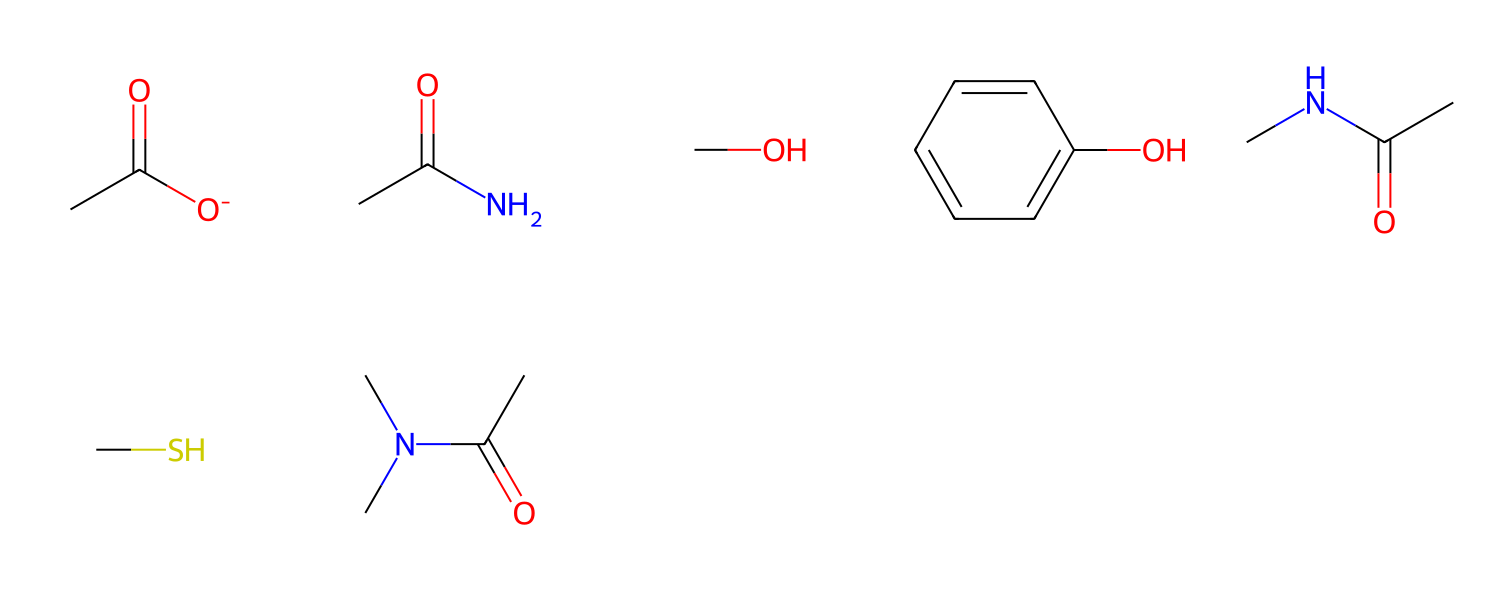

In [5]:
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df['smiles1'])], subImgSize=(300, 300), molsPerRow=5)

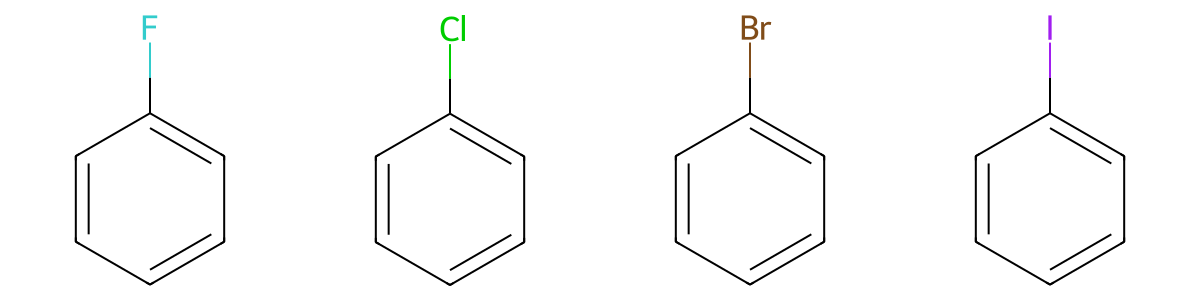

In [6]:
benzene = ['Fc1ccccc1', 'Clc1ccccc1', 'Brc1ccccc1', 'Ic1ccccc1']

def rotate_mol(mol, angle_deg):
    mol = Chem.Mol(mol)  # copy
    AllChem.Compute2DCoords(mol)

    angle = np.deg2rad(angle_deg)
    rot = np.array([
        [np.cos(angle), -np.sin(angle)],
        [np.sin(angle),  np.cos(angle)]
    ])

    conf = mol.GetConformer()
    for i in range(mol.GetNumAtoms()):
        x, y, z = conf.GetAtomPosition(i)
        x, y = np.dot(rot, np.array([x, y]))
        conf.SetAtomPosition(i, (float(x), float(y), float(z)))

    return mol

benzene = [
    "Fc1ccccc1",
    "Clc1ccccc1",
    "Brc1ccccc1",
    "Ic1ccccc1"
]

mol_list = [rotate_mol(Chem.MolFromSmiles(s), 90) for s in benzene]

img = Draw.MolsToGridImage(
    mol_list,
    subImgSize=(300, 300),
    molsPerRow=4
)
img


In [7]:
rings = [F_ring, Cl_ring, Br_ring, I_ring]

for halogen in rings:
    print(halogen['smiles1'].value_counts())



smiles1
CNC(C)=O        98
CO              24
CC(=O)N(C)C     19
CC(=O)[O-]      11
OC1=CC=CC=C1     9
CC(N)=O          6
CS               1
Name: count, dtype: int64
smiles1
CNC(C)=O        391
OC1=CC=CC=C1     40
CO               24
CC(N)=O          22
CC(=O)[O-]       16
CS                3
CC(=O)N(C)C       2
Name: count, dtype: int64
smiles1
CNC(C)=O        87
OC1=CC=CC=C1     8
CC(=O)[O-]       7
CC(N)=O          4
CO               1
Name: count, dtype: int64
smiles1
CNC(C)=O        71
CO               2
OC1=CC=CC=C1     2
CC(N)=O          1
CC(=O)[O-]       1
Name: count, dtype: int64


# Amide Geoemtry Pick + Generation

In [8]:
# filter out 
F_amide = F_ring.query('smiles1 == "CNC(C)=O" & charge0 == 0.0')
Cl_amide = Cl_ring.query('smiles1 == "CNC(C)=O" & charge0 == 0.0')
Br_amide = Br_ring.query('smiles1 == "CNC(C)=O" & charge0 == 0.0')
I_amide = I_ring.query('smiles1 == "CNC(C)=O" & charge0 == 0.0')

df_list = [F_amide, Cl_amide, Br_amide, I_amide]

def mean_med(df_list, column):
    for df in df_list:
        print(f"mean: {df[column].mean()}, median: {df[column].median()}")

def plot_dist(df_list, column):
    for df in df_list:
        sns.histplot(df[column], kde=True, bins=25)
        plt.xlabel('Distance')
        plt.ylabel('Frequency')
        plt.title('Distribution of Distances with KDE')
        plt.show()

print(len(F_amide))
print(len(Cl_amide))
print(len(Br_amide))
print(len(I_amide))

98
377
84
62


In [9]:
# mean_med(df_list, 'dist')
# plot_dist(df_list, 'dist')


In [10]:
# mean_med(df_list, 'don_angle')
# plot_dist(df_list, 'don_angle')


In [11]:
# mean_med(df_list, 'acc_angle')
# plot_dist(df_list, 'acc_angle')


In [12]:
# mean_med(df_list, 'TOTAL')
# plot_dist(df_list, 'TOTAL')


# Pick Geometry for each Halogen

Criteria: average distance, donor angle, acceptor angle, total energy

In [13]:
# [dist, don_angle, acc_angle, TOTAL]
F_target = np.array([3.4270000000000005, 147.5855, 103.77349999999998, -3.4715163265306126])
Cl_target = np.array([3.4713043478260865, 152.33876811594203, 109.82942028985508, -5.062738461538461])
Br_target = np.array([3.2990476190476192, 163.66619047619048, 123.30428571428571, -8.578028571428572])
I_target = np.array([3.5121428571428566, 162.0335714285714, 118.80571428571429, -13.593511290322581])

F_distances = np.sqrt(((F_amide[['dist','don_angle','acc_angle', 'TOTAL']] - F_target)**2).sum(axis=1))
closest_index = F_distances.idxmin()
F_min = F_amide.loc[closest_index]

Cl_distances = np.sqrt(((Cl_amide[['dist','don_angle','acc_angle', 'TOTAL']] - Cl_target)**2).sum(axis=1))
closest_index = Cl_distances.idxmin()
Cl_min = Cl_amide.loc[closest_index]

Br_distances = np.sqrt(((Br_amide[['dist','don_angle','acc_angle', 'TOTAL']] - Br_target)**2).sum(axis=1))
closest_index = Br_distances.idxmin()
Br_min = Br_amide.loc[closest_index]

I_distances = np.sqrt(((I_amide[['dist','don_angle','acc_angle', 'TOTAL']] - I_target)**2).sum(axis=1))
closest_index = I_distances.idxmin()
I_min = I_amide.loc[closest_index]


In [ ]:
print(F_min.name)
print(Cl_min.name)
print(Br_min.name)
print(I_min.name)

3wff_123_LEU_BB_24_1997
3wtl_322_LEU_BB_1_5046
6u80_251_TRP_BB_26_3877
1y0x_63_PHE_BB_23_1010


In [ ]:
print(F_min['TOTAL'])
print(Cl_min['TOTAL'])
print(Br_min['TOTAL'])
print(I_min['TOTAL'])

print(F_min['don_angle'])
print(Cl_min['don_angle'])
print(Br_min['don_angle'])
print(I_min['don_angle'])

print(F_min['acc_angle'])
print(Cl_min['acc_angle'])
print(Br_min['acc_angle'])
print(I_min['acc_angle'])

print(F_min['dist'])
print(Cl_min['dist'])
print(Br_min['dist'])
print(I_min['dist'])

148.87
152.54
163.62
167.64
104.37
109.88
123.73
119.74
3.52
2.96
3.29
3.22


# Unopt EDA PES 

works? but geometry are different, not the most fair comparison (dispersion for Cl is greater than dispersion for Br?)

In [18]:
from scripts.parse import eda_output, energy_output
from scripts.plot import eda_pes, eda_pes_plot
import os
import pandas as pd
import matplotlib.pyplot as plt

parent = os.getcwd()
top = os.path.join(parent, 'dontypeEDA')
Famide = os.path.join(parent, 'F-amide')
Clamide = os.path.join(parent, 'Cl-amide')
Bramide = os.path.join(parent, 'Br-amide')
Iamide = os.path.join(parent, 'I-amide')

(np.float64(-0.9644), np.float64(3.4))


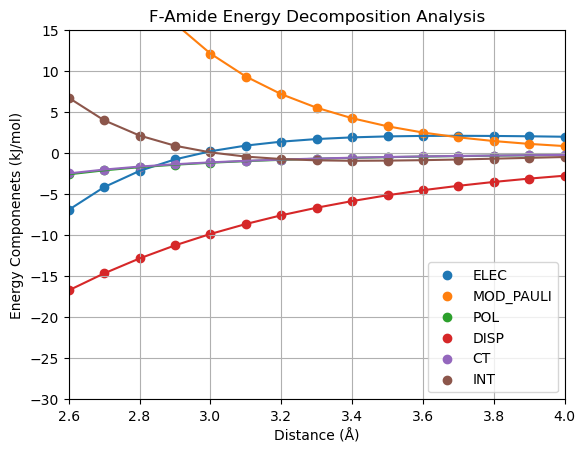

In [19]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Famide, f'unopt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})

min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('F-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Famide, 'EDA.png'))

(np.float64(-4.9557), np.float64(3.2))


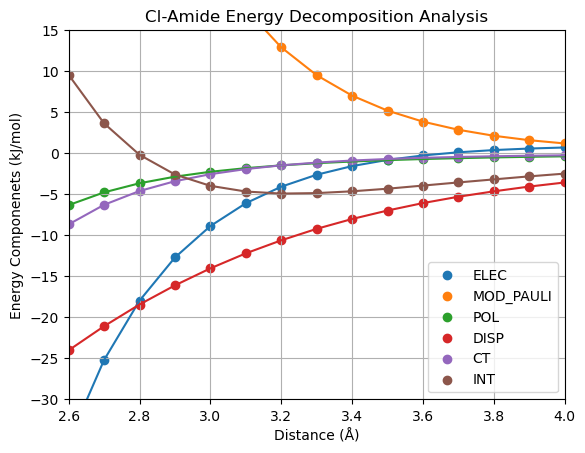

In [20]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Clamide, f'unopt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('Cl-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Clamide, 'EDA.png'))

(np.float64(-6.4529), np.float64(3.1))


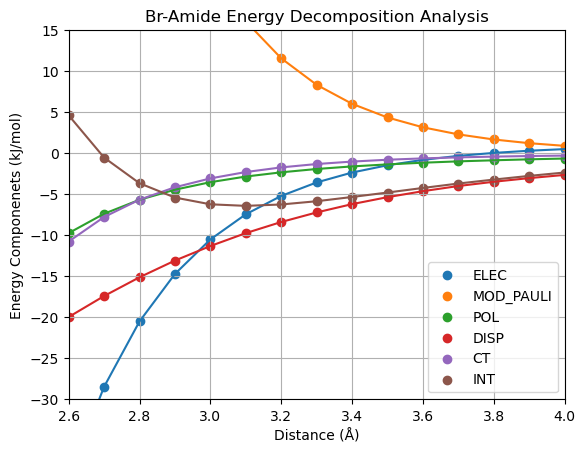

In [21]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Bramide, f'unopt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('Br-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Bramide, 'EDA.png'))

(np.float64(-16.8856), np.float64(3.0))


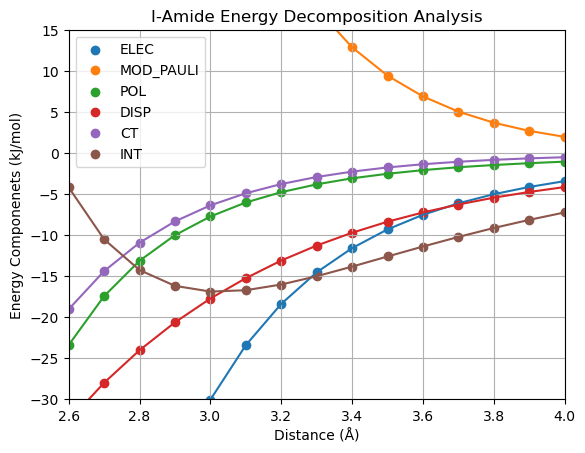

In [22]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Iamide, f'unopt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('I-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Iamide, 'UNOPT_EDA.png'))

# Opt EDA PES

# Full Opt EDA (full opt convergence only for I-amide)

(np.float64(-17.6382), np.float64(3.0))


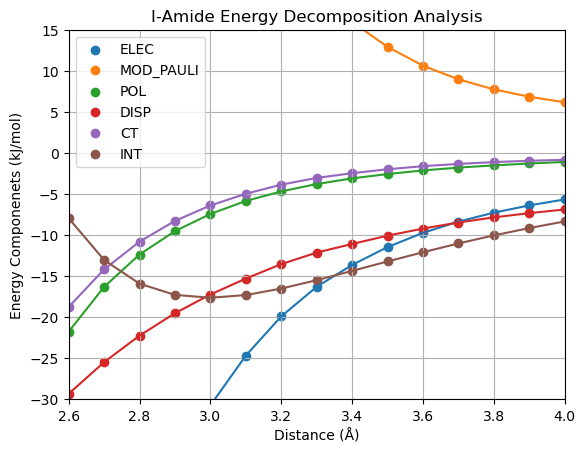

In [43]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Iamide, f'opt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('I-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Iamide, 'OPT_EDA.png'))

# 1-Opt-EDA

Use Optimized Geometry for TOTAL interaction energy minimum form Unopt-EDA (geom opt converged sucessfully for F-amide and I-amide)

(np.float64(-17.7691), np.float64(3.0))


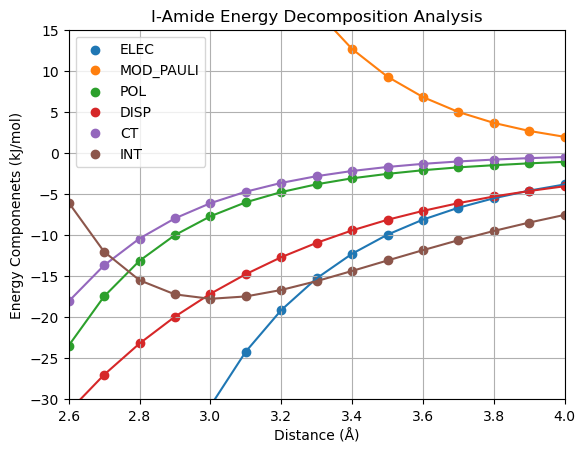

In [ ]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

# I-amide
for dist in dists:
    path = os.path.join(Iamide, f'1_opt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('I-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Iamide, 'OPT_EDA.png'))

(np.float64(-20.195), np.float64(3.5))


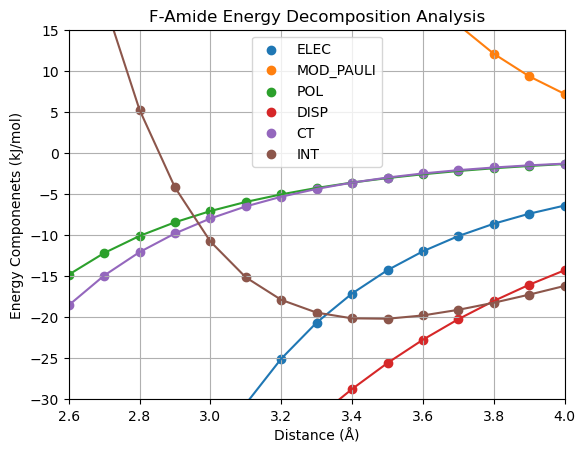

In [ ]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

# F-amide
for dist in dists:
    path = os.path.join(Famide, f'1_opt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.6, right=4.0)
ax.set_ylim(bottom=-30, top=15)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('F-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Famide, 'OPT_EDA.png'))

# I-Unopt EDA without C-X intrafragment distance correction (F-amide only, not good)

(np.float64(7.2579), np.float64(4.0))


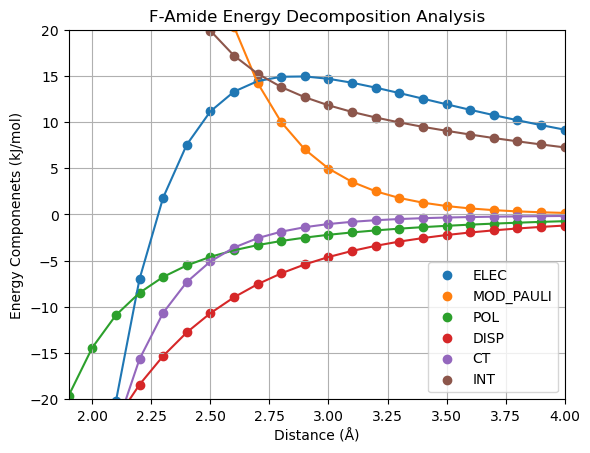

In [41]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Famide, f'I-unopt/oof/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=1.9, right=4.0)
ax.set_ylim(bottom=-20, top=20)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('F-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Famide, 'OPT_EDA.png'))

# I-Unopt EDA with C-X distance correction

Works? (Best one yet), but F-amide structure electrostaic is destabilizing??

(np.float64(1.3204), np.float64(5.0))


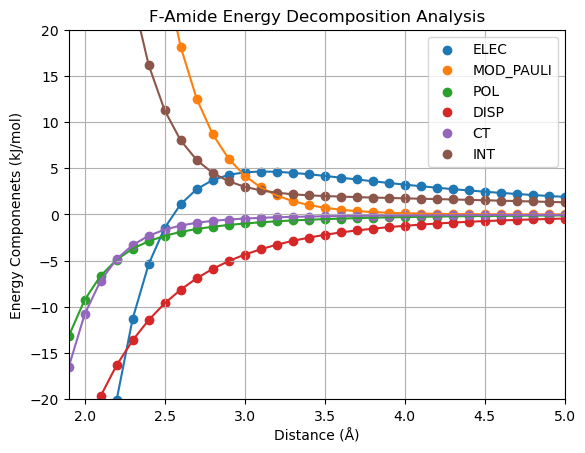

In [42]:
dists = [i/10 for i in range(19, 51)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Famide, f'I-unopt/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=1.9, right=5.0)
ax.set_ylim(bottom=-20, top=20)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('F-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Famide, 'OPT_EDA.png'))

(np.float64(-6.0012), np.float64(3.1))


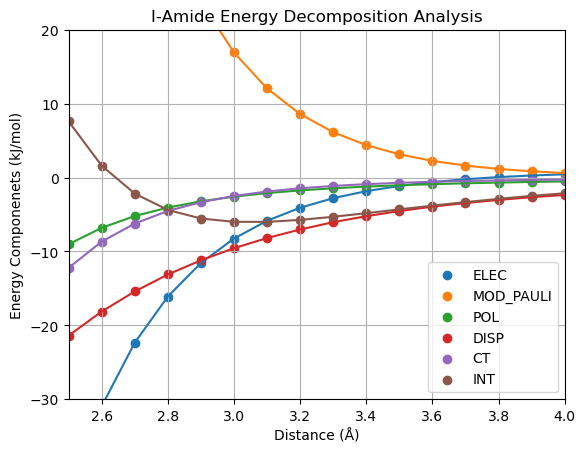

In [ ]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Clamide, f'I-unopt/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.5, right=4.0)
ax.set_ylim(bottom=-30, top=20)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('Cl-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Clamide, 'OPT_EDA.png'))

(np.float64(-10.1185), np.float64(3.0))


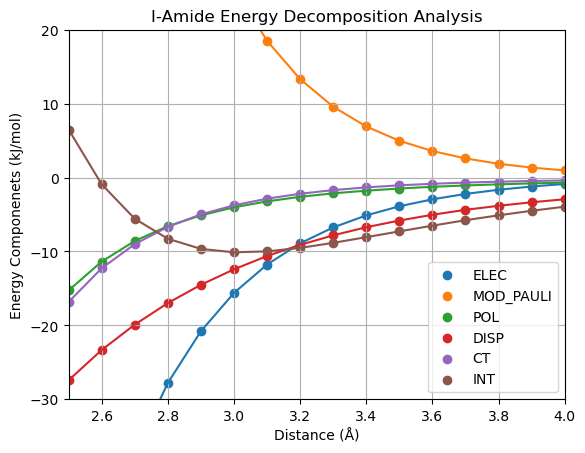

In [ ]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Bramide, f'I-unopt/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.5, right=4.0)
ax.set_ylim(bottom=-30, top=20)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('Br-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Bramide, 'OPT_EDA.png'))

(np.float64(-16.8856), np.float64(3.0))


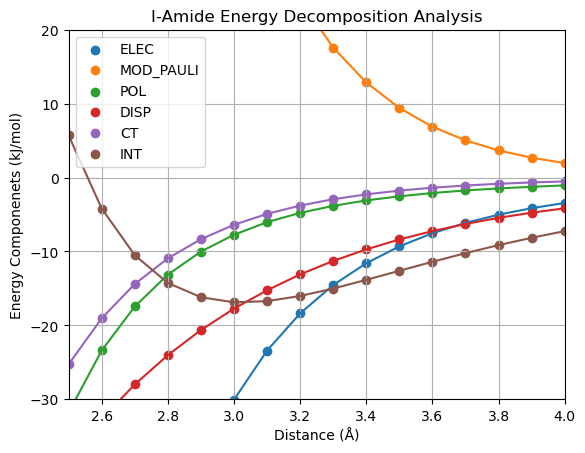

In [29]:
dists = [i/10 for i in range(19, 41)]

df = pd.DataFrame()

for dist in dists:
    path = os.path.join(Iamide, f'unopt_eda/eda_{dist:.1f}/eda.out')
    series = pd.Series(eda_output(path))
    dist_series = pd.Series([dist])
    series = pd.concat([dist_series, series])
    df = pd.concat([df, series.to_frame().T], ignore_index=True)
    df = df.sort_values(by=0)

df = df.rename(columns={0: "Dist"})
min_idx = df['INTERACTION'].idxmin()
well_depth = (df.loc[min_idx, 'INTERACTION'], df.loc[min_idx, 'Dist'])
print(well_depth)

fig, ax = plt.subplots()
eda_pes(ax, df)
eda_pes_plot(ax, df)
ax.grid(True)
ax.set_xlim(left=2.5, right=4.0)
ax.set_ylim(bottom=-30, top=20)
ax.set_xlabel('Distance (Å)')
ax.set_ylabel('Energy Componenets (kJ/mol)')
ax.set_title('I-Amide Energy Decomposition Analysis')
fig.savefig(os.path.join(Iamide, 'OPT_EDA.png'))